# SPC avanzado: atributos, cambios pequeños y autocorrelación

**Avanzado · Jornada 4 · Bloque 4.3 · diapositivas lento, grafico-p, funnel, cusum, arl, demo-residuos, bruto-residuos y ejercicio-ewma**

¿Cómo se vigila una avería que sube cinco vatios al día, una proporción diaria, una tasa por estación
o una serie horaria con ciclo? El cuaderno aplica gráficos p y u, funnel plot, CUSUM, EWMA y el ARL, y
repite la demo de Shewhart en bruto frente a residuos.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

La base de carga B-12 tiene, desde el 1 de diciembre de 2025, una avería que la hace perder **cinco
vatios más cada día**: una bombilla LED pequeña. ¿La ve un gráfico de control? Y, ya puestos: ¿cómo se
vigilan proporciones, tasas de unidades de tamaño muy distinto y series horarias con ciclo diario?

> **Mensaje clave del bloque:** el SPC no sustituye a los modelos; vigila lo que los modelos dejan
> como residuo.

## 1. El problema: unos vatios más cada día no hacen saltar a Shewhart

`energia_bases/diario.csv` tiene, por base y día, el **mínimo nocturno** (`minimo_nocturno_kw`): el
consumo más bajo entre las 3:00 y las 4:00, cuando casi no se carga nada. Si sube, algo se pierde.

In [2]:
# Tablas con coma decimal y tres ayudas de formato en español.
pd.set_option("display.float_format", lambda x: estilo.num(x, 2))


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha corta en español: 22-12-2025."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"


diario = pd.read_csv(DATOS / "energia_bases" / "diario.csv", parse_dates=["fecha"])
b12 = diario[diario["base_id"] == "B-12"].set_index("fecha")["minimo_nocturno_kw"]
b12 = b12.loc["2025-08-15":"2026-02-10"]          # 180 días, como en la diapositiva

INICIO_AVERIA = pd.Timestamp("2025-12-01")
referencia = b12.loc[:INICIO_AVERIA - pd.Timedelta(days=1)]   # días para fijar los límites
media_b12 = referencia.mean()
sigma_b12 = referencia.diff().abs().mean() / 1.128               # sigma del rango móvil
lci_b12, lcs_b12 = media_b12 - 3 * sigma_b12, media_b12 + 3 * sigma_b12
fuera_b12 = int(((b12 > lcs_b12) | (b12 < lci_b12)).sum())
print(f"Media {n(media_b12, 2)} kW, sigma {n(sigma_b12, 2)} kW; límites {n(lci_b12, 1)} a {n(lcs_b12, 1)} kW")
print(f"Puntos fuera de los límites en los 180 días: {fuera_b12}")

Media 14,82 kW, sigma 0,29 kW; límites 14,0 a 15,7 kW
Puntos fuera de los límites en los 180 días: 0


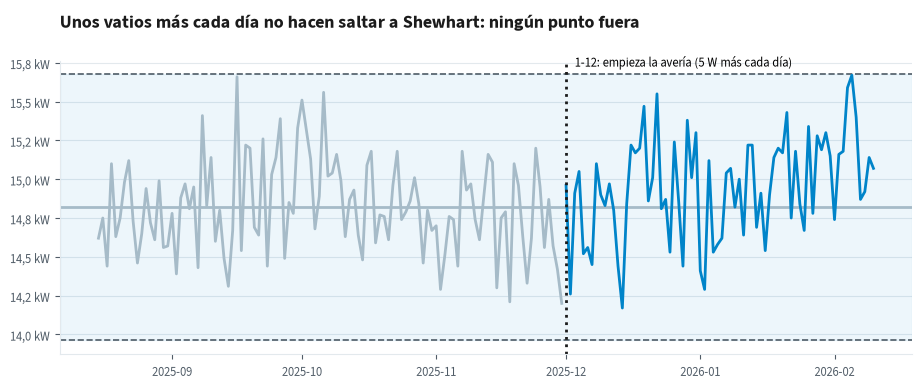

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axhspan(lci_b12, lcs_b12, color=estilo.AZUL, alpha=0.07)
for valor in (lci_b12, lcs_b12):
    ax.axhline(valor, color=estilo.TEXTO_2, linestyle="--", linewidth=1.2)
ax.axhline(media_b12, color=estilo.GRIS, linewidth=2)
ax.plot(referencia.index, referencia, color=estilo.GRIS)
ax.plot(b12.loc[INICIO_AVERIA:].index, b12.loc[INICIO_AVERIA:], color=estilo.AZUL)
ax.axvline(INICIO_AVERIA, color=estilo.TEXTO, linestyle=":")
ax.text(INICIO_AVERIA + pd.Timedelta(days=2), lcs_b12 + 0.05, "1-12: empieza la avería (5 W más cada día)", fontsize=9)
estilo.formato_eje(ax, decimales=1, sufijo=" kW")
ax.set_title("Unos vatios más cada día no hacen saltar a Shewhart: ningún punto fuera")
plt.show()

La serie azul está casi siempre por encima de la media y al final roza el límite, pero cada día, por
separado, es compatible con el ruido. Shewhart está hecho para cambios grandes de golpe; un cambio
pequeño y sostenido pide un gráfico **con memoria** (sección 4). Antes, dos herramientas para otro
tipo de datos.

## 2. Gráficos de atributos: las proporciones tienen sus propios límites

`indicadores/bicis_comunican_dia.csv`: por día, las bicis en servicio (*n*) y las que mandan al menos un
mensaje. Si cada bici comunica con probabilidad *p*, la proporción del día tiene desviación típica
√(*p*(1 − *p*)/*n*): los límites salen de la teoría y se abren los días con menos bicis.

p̄ = 98,74 %; bicis en servicio de 1.786 a 1.842
Fuera: 27-1-2026: comunican 1.377 de 1.813 (76,0 %)


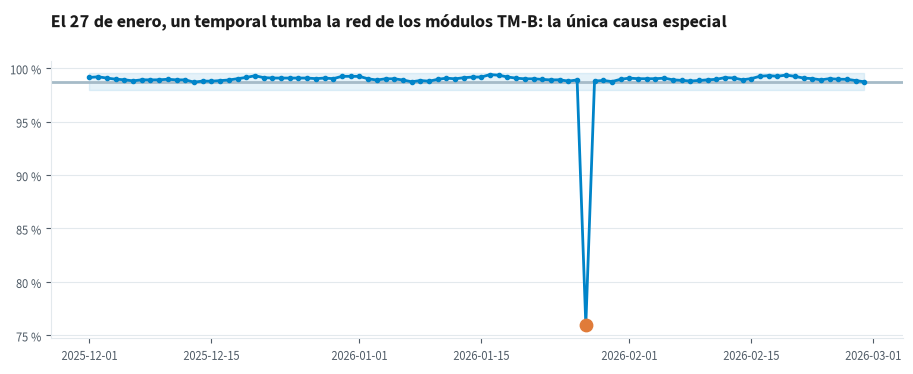

In [4]:
comunican = pd.read_csv(DATOS / "indicadores" / "bicis_comunican_dia.csv", parse_dates=["fecha"]).set_index("fecha")
tramo = comunican.loc["2025-12-01":"2026-02-28"]
p = tramo["bicis_que_comunican"] / tramo["bicis_en_servicio"]
p_media = tramo["bicis_que_comunican"].sum() / tramo["bicis_en_servicio"].sum()
sigma_p = np.sqrt(p_media * (1 - p_media) / tramo["bicis_en_servicio"])   # una por día
lci_p, lcs_p = p_media - 3 * sigma_p, p_media + 3 * sigma_p
fuera_p = p[(p < lci_p) | (p > lcs_p)]
print(f"p̄ = {pct(p_media, 2)}; bicis en servicio de {n(tramo['bicis_en_servicio'].min())} "
      f"a {n(tramo['bicis_en_servicio'].max())}")
for dia, valor in fuera_p.items():
    print(f"Fuera: {fecha(dia)}: comunican {n(tramo.loc[dia, 'bicis_que_comunican'])} de "
          f"{n(tramo.loc[dia, 'bicis_en_servicio'])} ({pct(valor)})")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(p.index, 100 * lci_p, 100 * lcs_p, step="mid", color=estilo.AZUL, alpha=0.1)
ax.axhline(100 * p_media, color=estilo.GRIS, linewidth=2)
ax.plot(p.index, 100 * p, color=estilo.AZUL, marker="o", markersize=3)
ax.scatter(fuera_p.index, 100 * fuera_p, s=80, color=estilo.NARANJA, zorder=5)
estilo.formato_eje(ax, sufijo=" %")
ax.set_title("El 27 de enero, un temporal tumba la red de los módulos TM-B: la única causa especial")
plt.show()

Advertencia práctica: con miles de casos al día, los límites binomiales son estrechísimos. Si casi
todos los puntos se salen, no es que todo sean señales: hay más variación de la que supone la
binomial. Entonces se usa el XmR sobre la proporción, o el gráfico p′ de Laney.

**El gráfico u**, primo del p, es para tasas: incidencias por unidad de exposición. Aquí, las
estaciones sin comunicación de `incidencias/incidencias.csv`, por estación y mes (de 30 días), con
límites ū ± 3√(ū/*n*), donde *n* son las estaciones-mes de cada mes.

11 días de tormenta o temporal: 25,7 estaciones sin comunicación al día, frente a 1,4 un día normal
Meses fuera: 2023-10 (2,37), 2023-11 (2,27), 2024-10 (2,37), 2024-11 (2,33), 2025-11 (3,30), 2026-02 (0,46), 2026-03 (0,53), 2026-04 (0,50), 2026-05 (0,53), 2026-06 (0,42), 2026-07 (0,48), 2026-08 (0,39), 2026-09 (0,70)


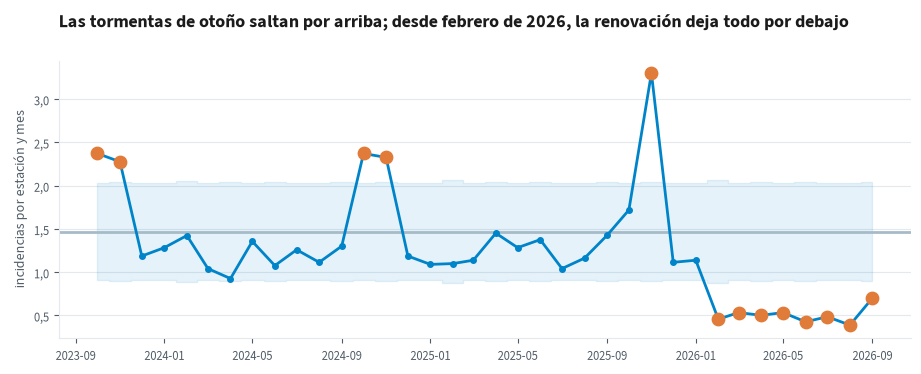

In [5]:
incidencias = pd.read_csv(DATOS / "incidencias" / "incidencias.csv")
incidencias["dia"] = bici.hora_local(incidencias["ts_apertura_utc"]).dt.tz_localize(None).dt.normalize()
sin_com = incidencias[incidencias["tipo"] == "estación sin comunicación"]
dias = pd.date_range("2023-10-01", "2026-09-30")
por_dia = sin_com.groupby("dia").size().reindex(dias, fill_value=0)

UMBRAL_TORMENTA = 10   # ← días con más estaciones sin comunicación que esto
tormenta = por_dia >= UMBRAL_TORMENTA
print(f"{int(tormenta.sum())} días de tormenta o temporal: {n(por_dia[tormenta].mean(), 1)} estaciones sin "
      f"comunicación al día, frente a {n(por_dia[~tormenta].mean(), 1)} un día normal")

por_mes = por_dia.resample("MS").sum()
exposicion = 40 * por_dia.resample("MS").size() / 30    # estaciones-mes de 30 días
u = por_mes / exposicion
fase1 = u.loc[:"2025-12"]                                 # antes de renovar las comunicaciones
u_media = por_mes.loc[:"2025-12"].sum() / exposicion.loc[:"2025-12"].sum()
lcs_u = u_media + 3 * np.sqrt(u_media / exposicion)
lci_u = (u_media - 3 * np.sqrt(u_media / exposicion)).clip(lower=0)
fuera_u = u[(u > lcs_u) | (u < lci_u)]
print("Meses fuera:", ", ".join(f"{m:%Y-%m} ({n(v, 2)})" for m, v in fuera_u.items()))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(u.index, lci_u, lcs_u, step="mid", color=estilo.AZUL, alpha=0.1)
ax.axhline(u_media, color=estilo.GRIS, linewidth=2)
ax.plot(u.index, u, color=estilo.AZUL, marker="o", markersize=4)
ax.scatter(fuera_u.index, fuera_u, s=80, color=estilo.NARANJA, zorder=5)
estilo.formato_eje(ax, decimales=1)
ax.set_ylabel("incidencias por estación y mes")
ax.set_title("Las tormentas de otoño saltan por arriba; desde febrero de 2026, la renovación deja todo por debajo")
plt.show()

Por arriba, los otoños de tormentas; por abajo, de febrero de 2026 en adelante, la renovación de las
comunicaciones de enero: un cambio de proceso, y bueno. Tocaría recalcular los límites con el
proceso nuevo.

## 3. Funnel plot: las estaciones pequeñas parecen extremas por puro azar

El centro de control quiere saber qué estaciones tienen más anclajes bloqueados. Alguien hace un
ranking por tasa (anclajes bloqueados por 1.000 viajes, de octubre de 2025 a septiembre de 2026) y
saca el «top 5». El funnel plot pone cada estación según su tamaño (viajes) y su tasa, con límites
que se abren para las pequeñas.

In [6]:
anclajes = incidencias[(incidencias["tipo"] == "anclaje bloqueado")
                       & (incidencias["dia"] >= "2025-10-01") & (incidencias["dia"] <= "2026-09-30")]
viajes_dia = pd.read_csv(DATOS / "uso_meteo" / "viajes_estacion_dia.csv", parse_dates=["fecha"])
viajes_dia = viajes_dia[(viajes_dia["fecha"] >= "2025-10-01") & (viajes_dia["fecha"] <= "2026-09-30")]
viajes = viajes_dia.groupby("estacion_id")["viajes"].sum()
bloqueos = anclajes.groupby("estacion_id").size().reindex(viajes.index, fill_value=0)

tasa = 1000 * bloqueos / viajes                      # por 1.000 viajes
tasa_media = bloqueos.sum() / viajes.sum()           # por viaje
# Límites de Poisson: media ± z · √(media / viajes); 3,09 deja fuera un 0,2 % (99,8 %), 1,96 un 5 %.
limite_998 = 1000 * (tasa_media + 3.09 * np.sqrt(tasa_media / viajes))
top5 = tasa.sort_values(ascending=False).head(5)
fuera_embudo = tasa[tasa > limite_998]
print(f"Media: {n(1000 * tasa_media, 2)} por 1.000 viajes")
print("Top 5 por tasa:", ", ".join(f"{e} ({n(tasa[e], 2)}; {n(viajes[e])} viajes)" for e in top5.index))
print("Fuera del embudo (99,8 %):", ", ".join(fuera_embudo.index))

Media: 0,46 por 1.000 viajes
Top 5 por tasa: E-03 (0,83; 432.861 viajes), E-35 (0,61; 59.340 viajes), E-40 (0,57; 38.687 viajes), E-31 (0,56; 30.304 viajes), E-05 (0,54; 188.303 viajes)
Fuera del embudo (99,8 %): E-03


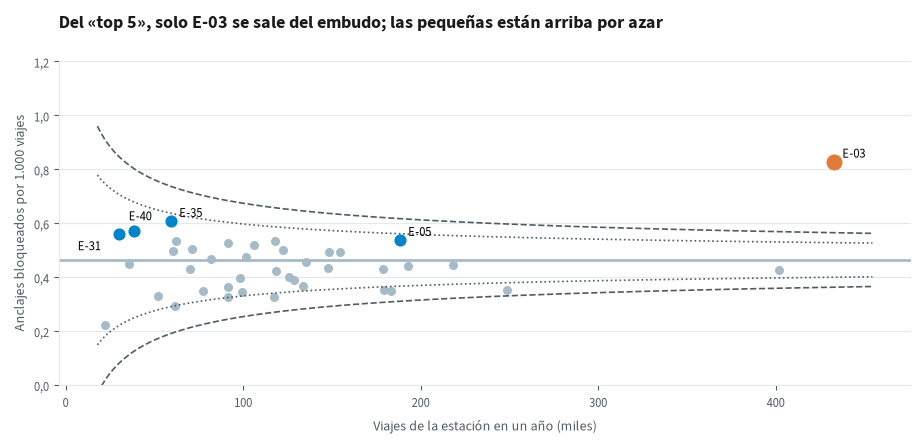

In [7]:
x = np.linspace(viajes.min() * 0.8, viajes.max() * 1.05, 300)
fig, ax = plt.subplots(figsize=(11, 4.2))
for z, estilo_linea in ((3.09, "--"), (1.96, ":")):
    for signo in (1, -1):
        ax.plot(x / 1000, 1000 * (tasa_media + signo * z * np.sqrt(tasa_media / x)), color=estilo.TEXTO_2,
                linestyle=estilo_linea, linewidth=1.2)
ax.axhline(1000 * tasa_media, color=estilo.GRIS, linewidth=2)
ax.scatter(viajes / 1000, tasa, s=30, color=estilo.GRIS)
ax.scatter(viajes[top5.index] / 1000, tasa[top5.index], s=60, color=estilo.AZUL, zorder=4)
ax.scatter(viajes[fuera_embudo.index] / 1000, tasa[fuera_embudo.index], s=110, color=estilo.NARANJA, zorder=5)
desplazamiento = {"E-31": (-30, -12), "E-40": (-4, 8)}     # para que no se pisen las etiquetas
for e in top5.index:
    ax.annotate(e, (viajes[e] / 1000, tasa[e]), xytext=desplazamiento.get(e, (6, 3)), textcoords="offset points",
                fontsize=9)
ax.set_ylim(0, 1.2)
ax.set_xlabel("Viajes de la estación en un año (miles)")
ax.set_ylabel("Anclajes bloqueados por 1.000 viajes")
estilo.formato_eje(ax, decimales=1)
estilo.formato_eje(ax, eje="x")
ax.set_title("Del «top 5», solo E-03 se sale del embudo; las pequeñas están arriba por azar")
plt.show()

La trampa: **señalar a las pequeñas**. Un ranking por tasa siempre pone arriba (y abajo) a las unidades
pequeñas, porque son las más ruidosas. Mandar a revisar las cinco primeras serían cuatro visitas para
nada. E-03 sí tiene causa: un lote de anclajes defectuoso instalado en septiembre de 2025. El funnel
plot vale para estaciones, celdas H3, hospitales o colegios.

## 4. CUSUM y EWMA: gráficos con memoria

Volvemos a B-12. Pasamos cada día a sigmas respecto a la referencia, *z* = (*x* − media) / sigma, y:

- **CUSUM** suma cada día *z* − *k* (una holgura de media sigma) y vuelve a cero si queda negativo.
  Mientras el proceso está en su sitio, la suma se pega a cero; con un cambio pequeño y sostenido,
  crece. Avisa cuando supera *h*.
- **EWMA** es una media con memoria: cada día, un λ = 20 % el dato nuevo y un 80 % lo que llevaba. Sus
  límites son mucho más estrechos que los de Shewhart, porque un promedio se mueve menos que un dato.

In [8]:
K, H = 0.5, 5.0          # ← CUSUM: holgura y umbral, en sigmas
LAMBDA, L = 0.2, 3.0     # ← EWMA: peso del dato nuevo y anchura de los límites

z = (b12.loc[INICIO_AVERIA:] - media_b12) / sigma_b12

# CUSUM superior, día a día.
suma, cusum_b12 = 0.0, []
for valor in z:
    suma = max(0.0, suma + valor - K)
    cusum_b12.append(suma)
cusum_b12 = pd.Series(cusum_b12, index=z.index)

# EWMA, con sus límites (se ensanchan los primeros días hasta estabilizarse).
media_movil, ewma_b12, limite_ewma = 0.0, [], []
for i, valor in enumerate(z, start=1):
    media_movil = LAMBDA * valor + (1 - LAMBDA) * media_movil
    ewma_b12.append(media_movil)
    limite_ewma.append(L * np.sqrt(LAMBDA / (2 - LAMBDA) * (1 - (1 - LAMBDA) ** (2 * i))))
ewma_b12, limite_ewma = pd.Series(ewma_b12, index=z.index), pd.Series(limite_ewma, index=z.index)

alarma_cusum = cusum_b12[cusum_b12 > H].index[0]
alarma_ewma = ewma_b12[ewma_b12 > limite_ewma].index[0]
print(f"CUSUM avisa el {fecha(alarma_cusum)}, {(alarma_cusum - INICIO_AVERIA).days} días tras el inicio")
print(f"EWMA avisa el {fecha(alarma_ewma)}, {(alarma_ewma - INICIO_AVERIA).days} días tras el inicio")

CUSUM avisa el 22-12-2025, 21 días tras el inicio
EWMA avisa el 22-12-2025, 21 días tras el inicio


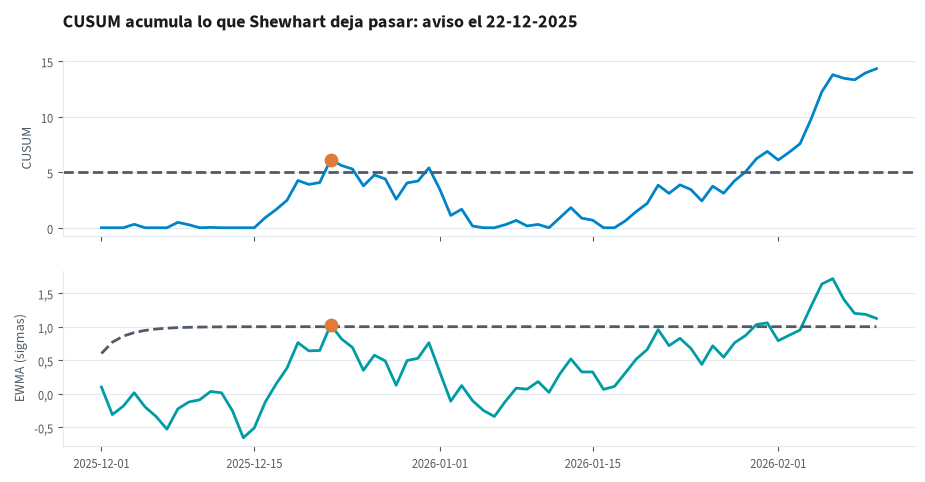

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax1.plot(cusum_b12.index, cusum_b12, color=estilo.AZUL)
ax1.axhline(H, color=estilo.TEXTO_2, linestyle="--")
ax1.scatter([alarma_cusum], [cusum_b12[alarma_cusum]], s=80, color=estilo.NARANJA, zorder=5)
ax1.set_ylabel("CUSUM")
ax1.set_title(f"CUSUM acumula lo que Shewhart deja pasar: aviso el {fecha(alarma_cusum)}")
ax2.plot(ewma_b12.index, ewma_b12, color=estilo.TURQUESA)
ax2.plot(limite_ewma.index, limite_ewma, color=estilo.TEXTO_2, linestyle="--")
ax2.scatter([alarma_ewma], [ewma_b12[alarma_ewma]], s=80, color=estilo.NARANJA, zorder=5)
ax2.set_ylabel("EWMA (sigmas)")
estilo.formato_eje(ax1, decimales=0)
estilo.formato_eje(ax2, decimales=1)
plt.show()

Tras la alarma, las curvas bajan un poco a finales de diciembre: es el ruido, que también existe con
avería. En la práctica, tras la alarma se investiga; no se espera a que se repita. Para cambios
pequeños, los dos funcionan parecido: CUSUM es algo mejor para un escalón de tamaño conocido, y EWMA
es más fácil de explicar y de pintar. Lo importante no es cuál, sino **con qué parámetros**.

## 5. Longitud media de racha (ARL): detectar antes cuesta falsas alarmas

El ARL es cuántos puntos pasan, de media, hasta la primera alarma. **Sin cambio**, es cada cuánto salta
una falsa alarma (lo queremos grande). **Con un cambio**, cuánto se tarda en verlo (lo queremos
pequeño). Lo simulamos: miles de series de ruido normal a las que se suma un cambio de la media de 0,
0,25… 3 sigmas, y para cada gráfico (Shewhart a 3σ, EWMA con λ = 0,2 y L = 3, CUSUM con k = 0,5 y
h = 5, los dos últimos por arriba y por abajo) apuntamos cuándo salta por primera vez.

In [10]:
N_SERIES = 4000   # ← series simuladas por caso: menos, más rápido y más ruidoso
cambios = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
azar = np.random.default_rng(2026)
limite_ewma_fijo = 3.0 * np.sqrt(0.2 / 1.8)    # límite asintótico del EWMA

filas = []
for cambio in cambios:
    ewma_s, sube, baja = np.zeros(N_SERIES), np.zeros(N_SERIES), np.zeros(N_SERIES)
    primera = np.zeros((3, N_SERIES))      # punto de la primera alarma de cada gráfico (0 = aún no)
    t = 0
    while (primera == 0).any() and t < 20_000:
        t += 1
        x = azar.normal(cambio, 1, N_SERIES)
        ewma_s = 0.2 * x + 0.8 * ewma_s
        sube = np.maximum(0, sube + x - 0.5)
        baja = np.maximum(0, baja - x - 0.5)
        alarmas = [np.abs(x) > 3, np.abs(ewma_s) > limite_ewma_fijo, (sube > 5) | (baja > 5)]
        for j, alarma in enumerate(alarmas):
            primera[j, alarma & (primera[j] == 0)] = t
    for j, grafico in enumerate(["Shewhart", "EWMA", "CUSUM"]):
        filas.append({"grafico": grafico, "cambio_sigma": cambio, "arl": primera[j].mean()})

arl_simulado = pd.DataFrame(filas).pivot(index="cambio_sigma", columns="grafico", values="arl")
arl_simulado.round(1)

grafico,CUSUM,EWMA,Shewhart
cambio_sigma,,,
"0,00","460,90","575,90","379,40"
"0,25","143,00","167,30","286,90"
"0,50","37,30","43,00","153,90"
"1,00","10,30","10,80","44,90"
"1,50","5,80","5,60","15,00"
"2,00","4,00","3,80","6,20"
"3,00","2,60","2,40","2,00"


La misma simulación está guardada en `indicadores/arl.csv` (4.000 series por caso, con otra semilla):
las dos deben parecerse mucho.

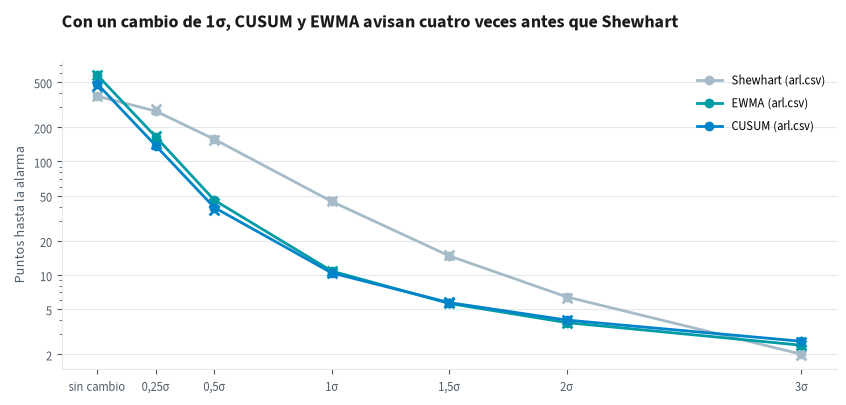

Sin cambio: Shewhart 376, EWMA 580, CUSUM 485 | con 1σ: Shewhart 44,3, EWMA 10,8, CUSUM 10,4


In [11]:
arl_csv = pd.read_csv(DATOS / "indicadores" / "arl.csv")
arl_csv["grafico"] = arl_csv["grafico"].str.split(" ").str[0]
arl_csv = arl_csv.pivot(index="desplazamiento_sigma", columns="grafico", values="arl")

fig, ax = plt.subplots(figsize=(10, 4))
colores = {"Shewhart": estilo.GRIS, "EWMA": estilo.TURQUESA, "CUSUM": estilo.AZUL}
for grafico, color in colores.items():
    ax.plot(arl_csv.index, arl_csv[grafico], color=color, marker="o", label=f"{grafico} (arl.csv)")
    ax.scatter(arl_simulado.index, arl_simulado[grafico], color=color, marker="x", s=50)
ax.set_yscale("log")
ax.set_yticks([2, 5, 10, 20, 50, 100, 200, 500])
estilo.formato_eje(ax)
ax.set_xticks(cambios, ["sin cambio", "0,25σ", "0,5σ", "1σ", "1,5σ", "2σ", "3σ"])
ax.set_ylabel("Puntos hasta la alarma")
ax.legend()
ax.set_title("Con un cambio de 1σ, CUSUM y EWMA avisan cuatro veces antes que Shewhart")
plt.show()
print("Sin cambio:", ", ".join(f"{g} {n(arl_csv.loc[0.0, g])}" for g in colores),
      "| con 1σ:", ", ".join(f"{g} {n(arl_csv.loc[1.0, g], 1)}" for g in colores))

Las cruces son vuestra simulación; las líneas, `arl.csv`. Sin cambio, Shewhart da una falsa alarma
cada unos 370 puntos (1 / 0,0027); con estos parámetros, EWMA y CUSUM dan incluso menos. Con un cambio
de 1σ, Shewhart tarda unos 44 puntos y los otros dos unos 10. Con saltos grandes, Shewhart es igual de
rápido: por eso no se tira.

El precio está en los parámetros: bajar *h* o subir λ adelanta la detección y trae más falsas
alarmas. El ARL es la forma honrada de elegir: decidís cuántas falsas alarmas podéis permitiros y,
con eso, el parámetro que antes detecta el cambio que os importa. Es el presupuesto de alarmas de la
Jornada 2 con otro nombre. Y todo esto **supone datos independientes**: es justo la demo que viene.

## 6. Demo: bruto frente a residuos

Algo que se hace muchísimo: coger la telemetría horaria de un equipo y ponerle un gráfico de control
encima. Aquí, el consumo horario de la base **B-09**, cuatro semanas de noviembre de 2025 (672 horas),
con los límites de Shewhart de siempre: media ± 3 sigmas, con la sigma del rango móvil.

**Antes de ejecutar:** si los datos fueran independientes, una falsa alarma cada 370 puntos: una o dos
en el mes. ¿Cuántas esperáis? Apuntad un número.

672 horas. Puntos fuera en bruto: 311 (unos 78 por semana)


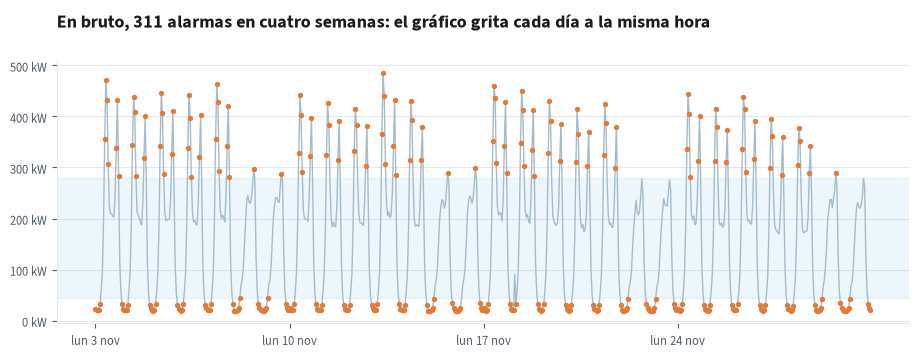

In [12]:
horario = pd.read_parquet(DATOS / "energia_bases" / "horario.parquet")
b09 = horario[horario["base_id"] == "B-09"].set_index("ts_utc")["kwh"]
b09.index = b09.index.tz_convert(bici.ZONA).tz_localize(None)       # hora local
serie = b09.loc["2025-11-03":"2025-11-30 23:00"]

media_h = serie.mean()
sigma_h = serie.diff().abs().mean() / 1.128
fuera_bruto = (serie > media_h + 3 * sigma_h) | (serie < media_h - 3 * sigma_h)
print(f"{len(serie)} horas. Puntos fuera en bruto: {int(fuera_bruto.sum())} "
      f"(unos {n(fuera_bruto.sum() / 4)} por semana)")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.axhspan(media_h - 3 * sigma_h, media_h + 3 * sigma_h, color=estilo.AZUL, alpha=0.07)
ax.plot(serie.index, serie, color=estilo.GRIS, linewidth=1)
ax.scatter(serie.index[fuera_bruto], serie[fuera_bruto], s=8, color=estilo.NARANJA, zorder=3)
ax.set_xticks(pd.to_datetime(["2025-11-03", "2025-11-10", "2025-11-17", "2025-11-24"]),
              ["lun 3 nov", "lun 10 nov", "lun 17 nov", "lun 24 nov"])
estilo.formato_eje(ax, sufijo=" kW")
ax.set_title(f"En bruto, {int(fuera_bruto.sum())} alarmas en cuatro semanas: el gráfico grita cada día a la misma hora")
plt.show()

¿Cuántas investigaríais? Ninguna: son los picos de cada mañana y tarde y los valles de cada noche. El
supuesto roto es la **independencia**: cada hora se parece mucho a la anterior (autocorrelación), el
rango móvil sale pequeño, los límites salen estrechos y el ciclo normal los rompe sin parar.

La solución: quitar primero lo que ya sabemos que pasa con la **STL de la Jornada 1** (periodo
semanal, 168 horas, sobre el logaritmo del consumo, robusta) y vigilar solo el residuo. En el residuo,
la sigma es su desviación típica.

Alarmas sobre los residuos: 1
  18-11-2025 a las 3:00: 91,1 kW (dos horas antes, 20,5 kW)


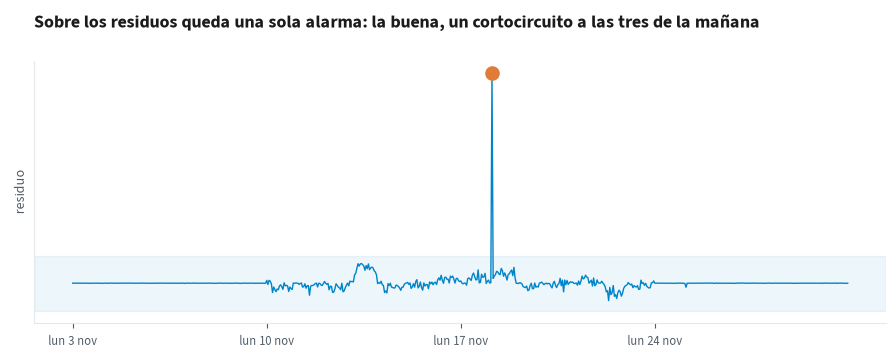

In [13]:
from statsmodels.tsa.seasonal import STL

residuo = pd.Series(STL(np.log(serie.to_numpy()), period=168, robust=True).fit().resid, index=serie.index)
centro, sigma_r = residuo.median(), residuo.std()
fuera_residuo = residuo[(residuo - centro).abs() > 3 * sigma_r]
print(f"Alarmas sobre los residuos: {len(fuera_residuo)}")
for hora in fuera_residuo.index:
    print(f"  {fecha(hora)} a las {hora.hour}:00: {n(serie[hora], 1)} kW (dos horas antes, {n(serie[hora - pd.Timedelta(hours=2)], 1)} kW)")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.axhspan(centro - 3 * sigma_r, centro + 3 * sigma_r, color=estilo.AZUL, alpha=0.07)
ax.plot(residuo.index, residuo, color=estilo.AZUL, linewidth=1)
ax.scatter(fuera_residuo.index, fuera_residuo, s=90, color=estilo.NARANJA, zorder=5)
ax.set_xticks(pd.to_datetime(["2025-11-03", "2025-11-10", "2025-11-17", "2025-11-24"]),
              ["lun 3 nov", "lun 10 nov", "lun 17 nov", "lun 24 nov"])
ax.set_yticks([])
ax.set_ylabel("residuo")
ax.set_title("Sobre los residuos queda una sola alarma: la buena, un cortocircuito a las tres de la mañana")
plt.show()

Ese cortocircuito, en el gráfico en bruto, apenas se distingue: a las tres de la mañana la base pasa de
unos 20 kW a 91, muy por debajo de los picos de cada día y dentro de los límites. **Entre las 311
alarmas del bruto no está la buena.** Cualquier serie con estacionalidad (llamadas por hora, consumos,
tráfico) primero se modela y después se vigila el residuo.

## 7. Ejercicio (equipos, 25 minutos): EWMA y CUSUM contra los detectores de la Jornada 2

La revancha de la Jornada 2: las mismas 40 bases, las mismas 16 averías sembradas (7 graduales, 7
escalones y 2 picos) y el mismo presupuesto de **5 alarmas al día**, pero con EWMA y CUSUM sobre los
residuos de cada base.

**El modelo de lo normal ya está hecho.** Para el mínimo nocturno diario no usamos la STL: su tendencia
se adaptaría a una avería lenta y se la comería. Lo normal de cada base es su **mediana de los 60 días
que acabaron hace 30**, corregida por el tipo de día (los festivos y fines de semana el mínimo es algo
más bajo); la escala, la MAD de esa misma ventana. El residuo, en sigmas, es lo que se separa de eso.

In [14]:
noche = diario.pivot(index="fecha", columns="base_id", values="minimo_nocturno_kw")   # una columna por base
calendario = pd.read_csv(DATOS / "uso_meteo" / "calendario.csv", parse_dates=["fecha"]).set_index("fecha")

# 1. Efecto del tipo de día, el mismo para todas las bases.
laborable = calendario["laborable"].reindex(noche.index)
efecto_dia = (noche - noche.median()).groupby(laborable).mean().mean(axis=1)
ajustado = noche.sub(laborable.map(efecto_dia), axis=0)

# 2. Lo normal: mediana de los 60 días que acabaron hace 30 (así una avería lenta tarda en colarse).
RETRASO, VENTANA = 30, 60   # días
pasado = ajustado.shift(RETRASO)
normal = pasado.rolling(VENTANA, min_periods=30).median()

# 3. La escala: MAD de la misma ventana, pasada a desviación típica (× 1,4826).
mad = pasado.rolling(VENTANA, min_periods=30).apply(lambda v: np.median(np.abs(v - np.median(v))), raw=True)
residuos = (ajustado - normal) / (1.4826 * mad)
dias_vigilados = residuos.dropna(how="all").index
print(f"Efecto del tipo de día: laborable {n(efecto_dia[True], 2)} kW; festivo o fin de semana {n(efecto_dia[False], 2)} kW")
print(f"Residuos de {residuos.shape[1]} bases desde el {fecha(dias_vigilados[0])}: {len(dias_vigilados)} días")

Efecto del tipo de día: laborable 0,18 kW; festivo o fin de semana −0,13 kW
Residuos de 40 bases desde el 29-12-2024: 641 días


Tres detectores sobre los mismos residuos. Tras cada alarma, CUSUM y EWMA vuelven a cero: la base se
revisa y se empieza a contar de nuevo.

- **Robusto de la Jornada 2** (referencia): alarma el día que el residuo pasa de un umbral.
- **CUSUM** con *k* y *h*.
- **EWMA** con λ y *L* (límite asintótico).

In [15]:
def cusum(z, k=0.5, h=5.0):
    """Alarmas (True/False) de un CUSUM superior sobre residuos en sigmas."""
    alarmas, suma = [], 0.0
    for valor in z:
        suma = 0.0 if np.isnan(valor) else max(0.0, suma + valor - k)
        alarmas.append(suma > h)
        if suma > h:
            suma = 0.0
    return alarmas


def ewma(z, lam=0.2, L=3.0):
    """Alarmas (True/False) de un EWMA superior sobre residuos en sigmas."""
    limite = L * np.sqrt(lam / (2 - lam))
    alarmas, media = [], 0.0
    for valor in z:
        media = 0.0 if np.isnan(valor) else lam * valor + (1 - lam) * media
        alarmas.append(media > limite)
        if media > limite:
            media = 0.0
    return alarmas


def por_base(detector, **parametros):
    """Aplica un detector a cada base: una tabla de alarmas como la de residuos."""
    return residuos.apply(lambda col: pd.Series(detector(col.to_numpy(), **parametros), index=col.index))

Para puntuar, la clave de las 16 averías (la que se reveló al final del ejercicio de la Jornada 2).
Una avería cuenta como detectada si hay una alarma en su base entre su inicio y su final; los días
hasta detectar se cuentan desde el inicio. Las alarmas fuera de las averías son **falsas alarmas**. B-23
es el caso integrador de esta mañana: sus alarmas desde marzo de 2026 no cuentan como falsas.

In [16]:
import io

clave = pd.read_csv(io.StringIO("""base_id,tipo,inicio,fin
B-03,gradual,2024-10-21,2025-06-10
B-40,gradual,2025-04-01,2026-01-12
B-26,gradual,2025-05-12,
B-19,gradual,2025-06-02,2025-11-03
B-28,gradual,2025-09-15,
B-12,gradual,2025-12-01,
B-35,gradual,2026-04-06,
B-02,escalón,2024-11-04,2024-12-02
B-11,escalón,2025-04-14,2025-05-05
B-21,escalón,2025-07-07,2025-10-06
B-29,escalón,2025-10-20,2025-11-17
B-31,escalón,2026-01-19,
B-33,escalón,2026-02-09,2026-03-16
B-37,escalón,2026-06-15,2026-07-06
B-09,pico,2025-11-18,2025-11-18
B-24,pico,2026-04-22,2026-04-22"""))
clave["inicio"] = pd.to_datetime(clave["inicio"])
clave["fin"] = pd.to_datetime(clave["fin"].fillna("2026-09-30"))

# Días con avería (o con el caso B-23) de cada base: ahí una alarma no es falsa.
con_averia = pd.DataFrame(False, index=noche.index, columns=noche.columns)
for averia in clave.itertuples():
    con_averia.loc[averia.inicio:averia.fin, averia.base_id] = True
con_averia.loc["2026-03-01":, "B-23"] = True


def puntuar(alarmas, nombre):
    """Una fila de la tabla del ejercicio."""
    dias = []
    for averia in clave.itertuples():
        avisos = alarmas.loc[averia.inicio:averia.fin, averia.base_id]
        avisos = avisos[avisos]
        dias.append((avisos.index[0] - averia.inicio).days if len(avisos) else np.nan)
    dias = pd.Series(dias, index=clave["base_id"])
    graduales = dias[(clave["tipo"] == "gradual").to_numpy()]
    vigiladas = alarmas.loc[dias_vigilados]
    return {"detector": nombre, "averías detectadas (de 16)": int(dias.notna().sum()),
            "graduales detectadas (de 7)": int(graduales.notna().sum()),
            "días hasta detectar las graduales (media)": graduales.mean(),
            "alarmas al día": vigiladas.sum(axis=1).mean(),
            "máximo de alarmas en un día": int(vigiladas.sum(axis=1).max()),
            "falsas alarmas al día": (vigiladas & ~con_averia.loc[dias_vigilados]).sum(axis=1).mean()}

**Vuestra tarea.** Ajustad los parámetros. La regla del juego de la diapositiva es no pasar de 5 alarmas
al día; mirad también la columna de falsas alarmas: **comparad los tres detectores con las mismas
falsas alarmas al día**, que es lo que dice el ARL. Rellenad la tabla de la diapositiva con vuestra
mejor configuración.

In [17]:
# ← Parámetros de partida: los de la diapositiva. Ajustadlos.
UMBRAL_ROBUSTO = 3.0          # alarma si el residuo pasa de este número de sigmas
K_CUSUM, H_CUSUM = 0.5, 5.0
LAMBDA_EWMA, L_EWMA = 0.2, 3.0

In [18]:
alarmas_robusto = residuos > UMBRAL_ROBUSTO
alarmas_cusum = por_base(cusum, k=K_CUSUM, h=H_CUSUM)
alarmas_ewma = por_base(ewma, lam=LAMBDA_EWMA, L=L_EWMA)
tabla = pd.DataFrame([puntuar(alarmas_robusto, f"Robusto J2 (umbral {n(UMBRAL_ROBUSTO, 1)})"),
                      puntuar(alarmas_ewma, f"EWMA (λ {n(LAMBDA_EWMA, 2)}; L {n(L_EWMA, 1)})"),
                      puntuar(alarmas_cusum, f"CUSUM (k {n(K_CUSUM, 1)}; h {n(H_CUSUM, 1)})")]).set_index("detector")
print("¿Dentro del presupuesto de 5 alarmas al día?", "sí" if (tabla["alarmas al día"] <= 5).all() else "NO")
tabla.T

¿Dentro del presupuesto de 5 alarmas al día? sí


detector,"Robusto J2 (umbral 3,0)","EWMA (λ 0,20; L 3,0)","CUSUM (k 0,5; h 5,0)"
averías detectadas (de 16),"15,00","15,00","15,00"
graduales detectadas (de 7),"7,00","7,00","7,00"
días hasta detectar las graduales (media),"57,14","31,00","29,71"
alarmas al día,"0,78","0,95","0,97"
máximo de alarmas en un día,"5,00","4,00","5,00"
falsas alarmas al día,"0,13","0,15","0,19"


## Qué os lleváis

- **Shewhart** ve los cambios grandes de golpe; para los pequeños y sostenidos, **CUSUM y EWMA**, que
  acumulan memoria.
- **Proporciones y tasas** tienen sus propios límites (gráficos p y u), que se abren con muestras
  pequeñas. Si casi todo se sale, hay sobredispersión: XmR o Laney.
- **Funnel plot** antes que ranking: las unidades pequeñas encabezan cualquier ranking por azar.
- El **ARL** pone el precio: detectar antes cuesta falsas alarmas. Se eligen los parámetros con las
  falsas alarmas que se pueden atender.
- **SPC con autocorrelación** es una trampa: 311 alarmas en bruto, una sobre los residuos. El SPC no
  sustituye a los modelos; vigila lo que los modelos dejan como residuo.